In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datetime import datetime, date

In [2]:
ds = xr.load_dataset("ERA5_features/grib_files/soil_moist_layer3.grib", engine="cfgrib")
var_daily = ds.swvl3.groupby(ds.swvl3.time.dt.date).mean()

Ignoring index file 'ERA5_features/grib_files/soil_moist_layer3.grib.5b7b6.idx' incompatible with GRIB file


In [3]:
var_daily = var_daily.reset_coords(['number', 'step', 'depthBelowLandLayer'], drop=True)

In [4]:
dates = var_daily.date.data
datetimes = np.zeros_like(dates)
for i in range(len(dates)):
    datetimes[i] = datetime.combine(dates[i], datetime.min.time())

In [5]:
var_daily.coords["time"] = ("date", datetimes)
var_daily = var_daily.swap_dims({"date": "time"})
var_daily = var_daily.reset_coords('date', drop=True)

In [6]:
var_daily = var_daily.sel(time=slice("1950-07", "2025-06"))
var_daily = var_daily.assign_coords({'month_day': 31*var_daily['time.month'] + var_daily['time.day']})
month = var_daily.time.dt.month
day = var_daily.time.dt.day
var_daily = var_daily.sel(time=~((month == 2) & (day == 29)))

In [7]:
ds_oro = xr.load_dataset("ERA5_features/grib_files/orography_1deg_res.grib", engine="cfgrib")
ds_oro = ds_oro.reset_coords(['number', 'time', 'step', 'surface', 'valid_time'], drop=True)

Ignoring index file 'ERA5_features/grib_files/orography_1deg_res.grib.5b7b6.idx' incompatible with GRIB file


In [8]:
g = 9.80665
lat = ds_oro.latitude
land_frac = ds_oro.lsm
mount_filt = xr.where(ds_oro.z/g < 1000, 1, 0)
land_filt = xr.where(land_frac > 0.5, 1, 0)

In [9]:
weights = np.cos(np.deg2rad(lat))*mount_filt*land_filt
weights.name = "weights"

In [10]:
lon_min = 4
lon_max = 42
lat_max = 72
lat_min = 59

var_daily_regmean = var_daily.sel(longitude=slice(lon_min,lon_max), latitude=slice(lat_max,lat_min)).weighted(weights).mean(dim=['longitude', 'latitude'])

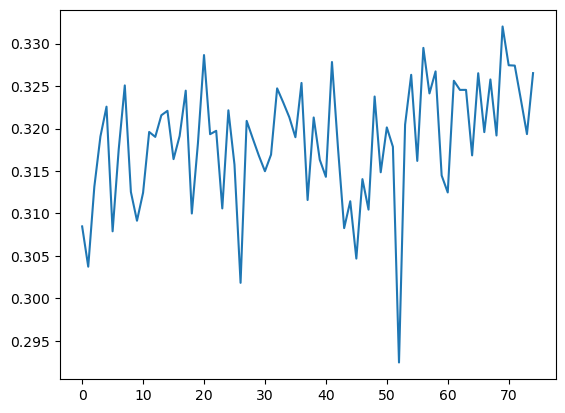

In [11]:
var_seasonmean_regmean = var_daily_regmean.coarsen(time=151).construct(time=("year", "date")).mean(dim='date')
plt.plot(var_seasonmean_regmean.year, var_seasonmean_regmean)

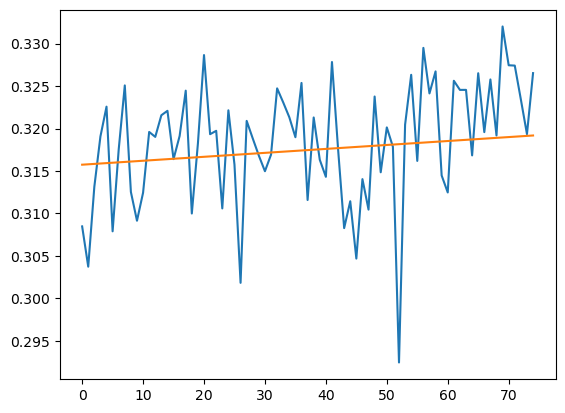

In [12]:
fit_par = np.polyfit(var_seasonmean_regmean[:60].year, var_seasonmean_regmean[:60], 1)
var_seasonmean_regmean_gws = np.polyval(fit_par, var_seasonmean_regmean.year)

plt.plot(var_seasonmean_regmean.year, var_seasonmean_regmean)
plt.plot(var_seasonmean_regmean.year, var_seasonmean_regmean_gws)

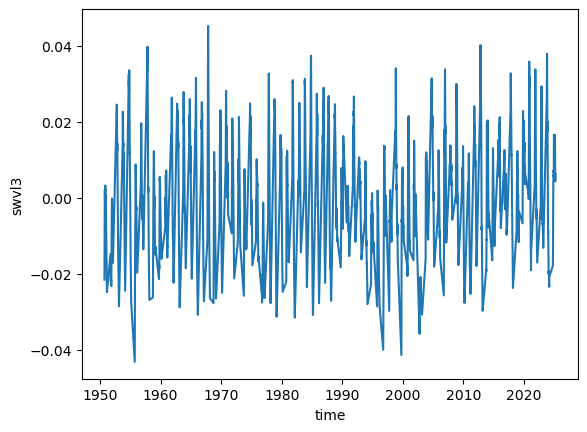

In [13]:
var_daily_regmean_detr = var_daily_regmean.coarsen(time=151).construct(time=("year", "date")) - var_seasonmean_regmean_gws[:, np.newaxis]
var_daily_regmean_detr = var_daily_regmean_detr.stack(day=("year", "date")).swap_dims({"day": "time"}).reset_coords(('day','year','date'), drop=True)
var_daily_regmean_detr.plot()

In [14]:
var_7dMean_regmean_detr = var_daily_regmean_detr.rolling(time=7, min_periods=7, center=True).mean() 
month = var_7dMean_regmean_detr.time.dt.month
day = var_7dMean_regmean_detr.time.dt.day
var_7dMean_regmean_detr = var_7dMean_regmean_detr.sel(time=~( ((month==10)&(day<4)) | ((month==2)&(day>25)) ))

var_7dMean_regmean_detr_train = var_7dMean_regmean_detr.sel(time=slice("1950-07", "2010-06"))

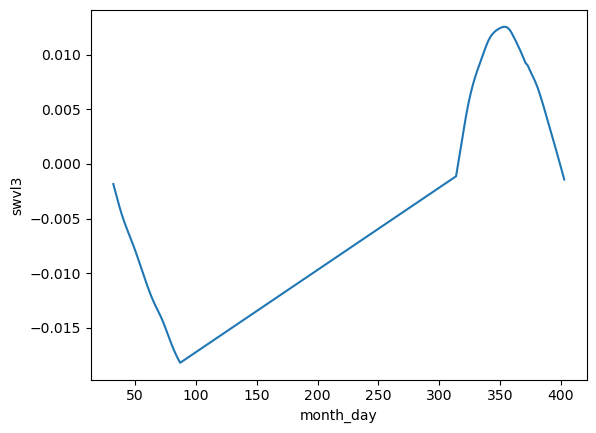

In [15]:
var_7dMean_regmean_detr_anom = var_7dMean_regmean_detr.groupby('month_day') - var_7dMean_regmean_detr_train.groupby('month_day').mean()
var_7dMean_regmean_detr_train.groupby('month_day').mean().plot()

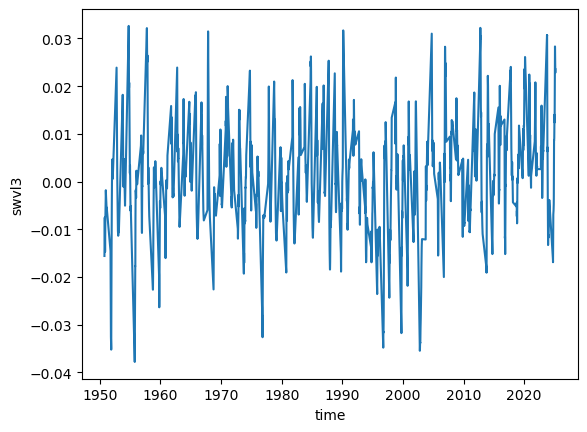

In [16]:
var_7dMean_regmean_detr_anom.plot()

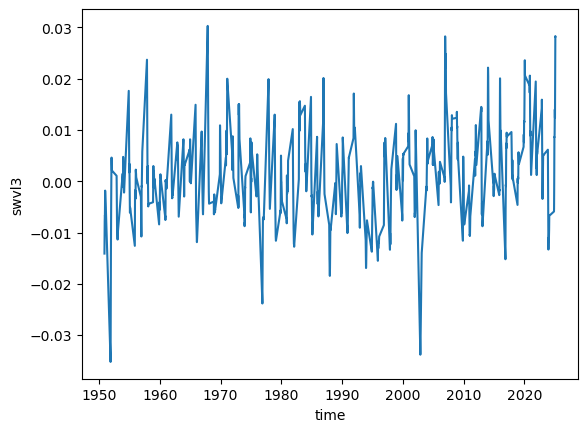

In [17]:
month = var_7dMean_regmean_detr_anom.time.dt.month
day = var_7dMean_regmean_detr_anom.time.dt.day
var_7dMean_regmean_detr_anom_week3 = var_7dMean_regmean_detr_anom.sel(time = ((month == 11) & (day >= 13)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 4)))
var_7dMean_regmean_detr_anom_week4 = var_7dMean_regmean_detr_anom.sel(time = ((month == 11) & (day >= 6)) | (month == 12) | ((month == 1) & (day <= 28)))
var_7dMean_regmean_detr_anom_week5 = var_7dMean_regmean_detr_anom.sel(time = ((month == 10) & (day >= 30)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 21)))
var_7dMean_regmean_detr_anom_week6 = var_7dMean_regmean_detr_anom.sel(time = ((month == 10) & (day >= 23)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 14)))
var_7dMean_regmean_detr_anom_week7 = var_7dMean_regmean_detr_anom.sel(time = ((month == 10) & (day >= 16)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 7)))
var_7dMean_regmean_detr_anom_week3.plot()

In [18]:
df_var_week3 = var_7dMean_regmean_detr_anom_week3.to_dataframe(name='soil_moist_lower')
df_var_week3 = df_var_week3.drop(['month_day'], axis=1)
df_var_week3

,soil_moist_lower
time,
1950-11-13,-0.014113
1950-11-14,-0.013418
1950-11-15,-0.012556
1950-11-16,-0.011631
1950-11-17,-0.010696
...,...
2025-01-31,0.027418
2025-02-01,0.027854
2025-02-02,0.028182


In [19]:
df_var_week4 = var_7dMean_regmean_detr_anom_week4.to_dataframe(name='soil_moist_lower')
df_var_week4 = df_var_week4.drop(['month_day'], axis=1)
df_var_week4

,soil_moist_lower
time,
1950-11-06,-0.013111
1950-11-07,-0.013529
1950-11-08,-0.013947
1950-11-09,-0.014321
1950-11-10,-0.014609
...,...
2025-01-24,0.025155
2025-01-25,0.025206
2025-01-26,0.025278


In [20]:
df_var_week5 = var_7dMean_regmean_detr_anom_week5.to_dataframe(name='soil_moist_lower')
df_var_week5 = df_var_week5.drop(['month_day'], axis=1)
df_var_week5

,soil_moist_lower
time,
1950-10-30,-0.010247
1950-10-31,-0.010727
1950-11-01,-0.011167
1950-11-02,-0.011564
1950-11-03,-0.011937
...,...
2025-01-17,0.018234
2025-01-18,0.020091
2025-01-19,0.021834


In [18]:
df_var_week6 = var_7dMean_regmean_detr_anom_week6.to_dataframe(name='soil_moist_lower')
df_var_week6 = df_var_week6.drop(['month_day'], axis=1)
df_var_week6

,soil_moist_lower
time,
1950-10-23,-0.007548
1950-10-24,-0.007600
1950-10-25,-0.007847
1950-10-26,-0.008230
1950-10-27,-0.008704
...,...
2025-01-10,0.012609
2025-01-11,0.012405
2025-01-12,0.012388


In [19]:
df_var_week7 = var_7dMean_regmean_detr_anom_week7.to_dataframe(name='soil_moist_lower')
df_var_week7 = df_var_week7.drop(['month_day'], axis=1)
df_var_week7

,soil_moist_lower
time,
1950-10-16,-0.011284
1950-10-17,-0.010589
1950-10-18,-0.009850
1950-10-19,-0.009153
1950-10-20,-0.008526
...,...
2025-01-03,0.014012
2025-01-04,0.013952
2025-01-05,0.013819


In [19]:
df_var_week3.to_csv('sm_lower_NE_week3_detr.csv')

In [21]:
df_var_week4.to_csv('sm_lower_NE_week4_detr.csv')
df_var_week5.to_csv('sm_lower_NE_week5_detr.csv')

In [20]:
df_var_week6.to_csv('sm_lower_NE_week6_detr.csv')
df_var_week7.to_csv('sm_lower_NE_week7_detr.csv')